<a href="https://colab.research.google.com/github/dev-jpzheng/ailearn/blob/main/d2l_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 3.2 linear regression implementation from scratch

In [ ]:
!pip install --no-deps d2l==0.17.6

In [ ]:
%matplotlib inline
import math, time
import numpy as np
import torch
from d2l import torch as d2l

class Timer:
  def __init__(self):
    self.times=[]
    self.start()

  def start(self):
    self.tik=time.time()

  def stop(self):
    self.times.append(time.time()-self.tik)
    return self.times[-1]

  def avg(self):
    return sum(self.times)/len(self.times)

  def sum(self):
    return sum(self.times)

  def cumsum(self):
    return np.array(self.times).cumsum().tolist()

n=10000
a=torch.ones([n])
b=torch.ones([n])

c=torch.zeros([n])
timer=Timer()

for i in range(n):
  c[i]=a[i]+b[i]
print(f'{timer.stop():.5f} sec')

timer.start()
d=a+b
print(f'{timer.stop():.5f} sec')

0.10730 sec
0.00050 sec


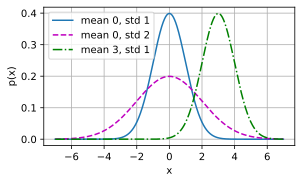

In [ ]:
def normal(x, mu, sigma):
  p=1/math.sqrt(2*math.pi*sigma**2)
  return p*np.exp(-0.5*(x-mu)**2/sigma**2)

x=np.arange(-7,7,0.01)

params=[(0,1), (0,2), (3,1)]
d2l.plot(x,[normal(x,mu, sigma) for mu, sigma in params],xlabel='x',ylabel='p(x)',figsize=(4.5,2.5),legend=[f'mean {mu}, std {sigma}' for mu, sigma in params])


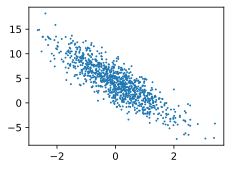

In [ ]:
import random

def synthetic_data(w, b, num_examples):
  X=torch.normal(0, 1, (num_examples, len(w)))
  y=torch.matmul(X, w) + b
  y+=torch.normal(0, 0.01, y.shape)
  return X, y.reshape(-1, 1)

true_w=torch.tensor([2, -3.4])
true_b=4.2
features, lables=synthetic_data(true_w, true_b, 1000)
lables.shape

d2l.set_figsize()
d2l.plt.scatter(features[:, 1].detach().numpy(), lables.detach().numpy(), 1)

In [ ]:
def data_iter(batch_size, features, labels):
  num_examples=len(features)
  indices=list(range(num_examples))
  random.shuffle(indices)
  for i in range(0, num_examples, batch_size):
    batch_indices = torch.tensor(indices[i: min(i+batch_size, num_examples)])
    yield features[batch_indices], labels[batch_indices]

batch_size=10
# for X, y in data_iter(batch_size, features, lables):
#   print(X, '\n', y)
#   break;
w=torch.normal(0, 0.01, size=(2, 1), requires_grad=True)
b=torch.zeros(1, requires_grad=True)

def linreg(X, w, b):
  return torch.matmul(X, w) + b

def squared_loss(y_hat, y):
  return (y_hat-y.reshape(y_hat.shape))**2/2

def sgd(params, lr, batch_size):
  with torch.no_grad():
    for param in params:
      param -= lr*param.grad/batch_size
      param.grad.zero_()

In [ ]:
lr=0.01
num_epochs=8
net=linreg
loss=squared_loss

for epoch in range(num_epochs):
  for X, y in data_iter(batch_size, features, lables):
    l=loss(net(X, w, b), y)
    l.sum().backward()
    sgd([w, b], lr, batch_size)
  with torch.no_grad():
    train_l=loss(net(features, w, b), lables)
    print(f'epoch {epoch+1}, loss {float(train_l.mean()):f}')

epoch 1, loss 2.250487
epoch 2, loss 0.314675
epoch 3, loss 0.044862
epoch 4, loss 0.006544
epoch 5, loss 0.001000
epoch 6, loss 0.000189
epoch 7, loss 0.000068
epoch 8, loss 0.000050


In [ ]:
w, b

(tensor([[ 1.9994],
         [-3.3977]], requires_grad=True),
 tensor([4.1983], requires_grad=True))

## 3.3 concise implementation of linear regression

In [ ]:
import numpy as np
import torch
from torch.utils import data
from d2l import torch as d2l

true_w=torch.tensor([2, -3.4])
true_b=4.2
features, labels=d2l.synthetic_data(true_w, true_b, 1000)

def load_array(data_arrays, batch_sie, is_train=True):
  dataset=data.TensorDataSet(*data_arrays)
  return data.DataLoader(dataset, batch_size, shuffle=is_train)

batch_size=10
data_iter=load_array((features))


float

In [ ]:
import numpy as np
import torch
from torch.utils import data
from d2l import torch as d2l

true_w=torch.tensor([2, -3.4])
true_b=4.2
features, labels=d2l.synthetic_data(true_w, true_b, 1000)

def load_array(data_arrays, batch_sie, is_train=True):
  dataset=data.TensorDataSet(*data_arrays)
  return data.DataLoader(dataset, batch_size, shuffle=is_train)

batch_size=10
data_iter=load_array((features))


float

In [ ]:
import numpy as np
import torch
from torch.utils import data
from d2l import torch as d2l

true_w=torch.tensor([2, -3.4])
true_b=4.2
features, labels=d2l.synthetic_data(true_w, true_b, 1000)

def load_array(data_arrays, batch_sie, is_train=True):
  dataset=data.TensorDataset(*data_arrays)
  return data.DataLoader(dataset, batch_size, shuffle=is_train)

batch_size=10
data_iter=load_array((features, labels), batch_size)

# next(iter(data_iter))


[tensor([[ 0.8695, -0.6362],
         [ 0.7049,  0.8024],
         [-0.1894,  1.1659],
         [ 0.4855, -0.8514],
         [-0.8758,  0.1055],
         [ 0.8640,  2.2874],
         [ 2.7784,  0.2213],
         [-0.5580, -0.0545],
         [-2.2046,  0.4769],
         [ 2.4845, -0.4671]]),
 tensor([[ 8.0924],
         [ 2.8559],
         [-0.1625],
         [ 8.0785],
         [ 2.0927],
         [-1.8402],
         [ 8.9975],
         [ 3.2854],
         [-1.8441],
         [10.7574]])]

In [ ]:
from torch import nn

net=nn.Sequential(nn.Linear(2, 1))

net[0].weight.data.normal_(0, 0.01)
net[0].bias.data.fill_(0)

loss=nn.MSELoss()
trainer=torch.optim.SGD(net.parameters(), lr=0.03)

num_epocs=3
for epoch in range(num_epocs):
  for X, y in data_iter:
    l=loss(net(X), y)
    trainer.zero_grad()
    l.backward()
    trainer.step()
  l=loss(net(features), labels)
  print(f'epoch {epoch+1}: loss {l:f}')

epoch 1: loss 0.000208
epoch 2: loss 0.000093
epoch 3: loss 0.000093


In [ ]:
w=net[0].weight.data
b=net[0].bias.data
w, b

(tensor([[ 2.0003, -3.3996]]), tensor([4.1995]))

## 3.5 Fashion-MNIST

In [ ]:
%matplotlib inline
import torch, torchvision
from torch.utils import data
from torchvision import transforms
from d2l import torch as d2l

d2l.use_svg_display()

trans=transforms.ToTensor()
mnist_train=torchvision.datasets.FashionMNIST(root='./data', train=True, transform=trans, download=True)
mnist_test=torchvision.datasets.FashionMNIST(root='./data', train=False, transform=trans, download=True)

# len(mnist_train), len(mnist_test)

(60000, 10000)

array([<Axes: title={'center': 'ankle boot'}>,
       <Axes: title={'center': 't-shirt'}>,
       <Axes: title={'center': 't-shirt'}>,
       <Axes: title={'center': 'dress'}>,
       <Axes: title={'center': 't-shirt'}>,
       <Axes: title={'center': 'pullover'}>,
       <Axes: title={'center': 'sneaker'}>,
       <Axes: title={'center': 'pullover'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 't-shirt'}>,
       <Axes: title={'center': 'ankle boot'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 'sneaker'}>,
       <Axes: title={'center': 'ankle boot'}>,
       <Axes: title={'center': 'trouser'}>,
       <Axes: title={'center': 't-shirt'}>], dtype=object)

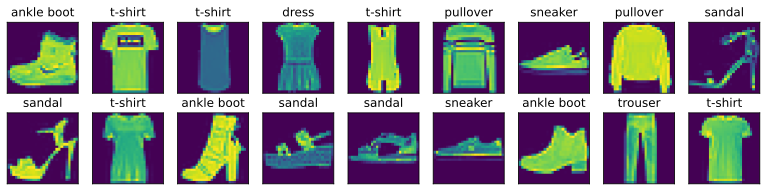

In [ ]:
# mnist_train[0][0].shape

def get_fashion_mnist_labels(labels):
  text_labels=['t-shirt', 'trouser', 'pullover', 'dress', 'coat', 'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']
  return [text_labels[int(i)] for i in labels]

def show_images(imgs, num_rows, num_cols, titles=None, scale=1.5):
  figsize=(num_cols*scale, num_rows*scale)
  _, axes=d2l.plt.subplots(num_rows, num_cols, figsize=figsize)
  axes=axes.flatten()
  for i, (ax, img) in enumerate(zip(axes, imgs)):
    if torch.is_tensor(img):
      ax.imshow(img.numpy())
    else:
      ax.imshow(img)
    ax.axes.get_xaxis().set_visible(False)
    ax.axes.get_yaxis().set_visible(False)
    if titles:
      ax.set_title(titles[i])
  return axes

X, y=next(iter(data.DataLoader(mnist_train, batch_size=18)))
show_images(X.reshape(18, 28, 28), 2, 9, titles=get_fashion_mnist_labels(y))

In [ ]:
batch_size=256

def get_dataloader_workers():
  return 2

train_iter=data.DataLoader(mnist_train, batch_size, shuffle=True, num_workers=get_dataloader_workers())

timer=d2l.Timer()
for X, y in train_iter:
  continue;
print(f'{timer.stop():.2f} sec')

6.09 sec


In [ ]:
def load_data_fashion_mnist(batch_size, resize=None):
  trans=[transforms.ToTensor()]
  if resize:
    trans.insert(0, transforms.Resize(resize))
  trans=transforms.Compose(trans)
  mnist_train=torchvision.datasets.FashionMNIST(root='./data', train=True, transform=trans, download=True)
  mnist_test=torchvision.datasets.FashionMNIST(root='./data', train=False, transform=trans, download=True)
  return (data.DataLoader(mnist_train, batch_size, shuffle=True, num_workers=get_dataloader_workers()),
          data.DataLoader(mnist_test, batch_size, shuffle=False, num_workers=get_dataloader_workers()))

train_iter, test_iter=load_data_fashion_mnist(32, resize=64)
for X, y in train_iter:
  print(X.shape, X.dtype, y.shape, y.dtype)
  break

torch.Size([32, 1, 64, 64]) torch.float32 torch.Size([32]) torch.int64


## 3.6 softmax implementation from scratch

In [ ]:
import torch
from IPython import display
from d2l import torch as d2l

batch_size=256
train_iter, test_iter=d2l.load_data_fashion_mnist(batch_size)

num_inputs=784
num_outputs=10

W=torch.normal(0, 0.01, size=(num_inputs, num_outputs), requires_grad=True)
b=torch.zeros(num_outputs, requires_grad=True)

X=torch.tensor([[1.0, 2.0, 3.0], [4.0, 5.0, 6.0]])
X.sum(0, keepdim=True), X.sum(1, keepdim=True)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


(tensor([[5., 7., 9.]]),
 tensor([[ 6.],
         [15.]]))

In [ ]:
def softmax(X):
  X_exp=torch.exp(X)
  partition=X_exp.sum(1, keepdim=True)
  return X_exp/partition

def net(X):
  return softmax(torch.matmul(X.reshape(-1, W.shape[0]), W) + b)

def cross_entropy(y_hat, y):
  return -torch.log(y_hat[range(len(y_hat)), y])

def accuracy(y_hat, y):
  if len(y_hat.shape) > 1 and y_hat.shape[1] > 1:
    y_hat=y_hat.argmax(axis=1)
  cmp=y_hat.type(y.dtype)==y
  return float(cmp.type(y.dtype).sum())

X=torch.randn((2, 5))
# X_prob=softmax(X)
# X_prob, X_prob.sum(1)
y=torch.tensor([0, 2])
y_hat=torch.tensor([[0.1, 0.3, 0.6], [0.3, 0.2, 0.5]])
y_hat[[0, 1], y]
cross_entropy(y_hat, y)
accuracy(y_hat, y)/len(y)

0.5

In [ ]:
class Accumulator:
  def __init__(self, n):
    self.data=[0.0]*n

  def add(self, *args):
    self.data=[a+float(b) for a, b in zip(self.data, args)]

  def reset(self):
    self.data=[0.0]*len(self.data)

  def __getitem__(self, idx):
    return self.data[idx]

def evaluate_accuracy(net, data_iter):
  if isinstance(net, torch.nn.Module):
    net.eval()
  metric=Accumulator(2)
  with torch.no_grad():
    for X, y in data_iter:
      metric.add(accuracy(net(X), y), y.numel())
  return metric[0]/metric[1]

evaluate_accuracy(net, test_iter)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


0.0442

In [ ]:
def train_epoch(net, train_iter, loss, updater):
  if isinstance(net, torch.nn.Module):
    net.train()
  metric=Accumulator(3)
  for X, y in train_iter:
    y_hat=net(X)
    l=loss(y_hat, y)
    if isinstance(updater, torch.optim.Optimizer):
      updater.zero_grad()
      l.mean().backward()
      updater.step()
    else:
      l.sum().backward()
      updater(X.shape[0])
    metric.add(float(l.sum()), accuracy(y_hat, y), y.numel())
  return metric[0]/metric[2], metric[1]/metric[2]

class Animator:
  def __init__(self, xlabel=None, ylabel=None, legend=None, xlim=None, ylim=None, xscale='linear', yscale='linear', fmts=('-', 'm--', 'g-.', 'r:'), nrows=1, ncols=1, figsize=(3.5, 2.5)):
    if legend is None:
      legend=[]
    d2l.use_svg_display()
    self.fig, self.axes=d2l.plt.subplots(nrows, ncols,figsize=figsize)
    if nrows*ncols == 1:
      self.axes=[self.axes,]
    self.config_axes=lambda: d2l.set_axes(self.axes[0], xlabel, ylabel, xlim, ylim, xscale, yscale, legend)
    self.X, self.Y, self.fmts=None, None, fmts

  def add(self, x, y):
    if not hasattr(y, "__len__"):
      y=[y]
    n=len(y)
    if not hasattr(x, "__len__"):
      x=[x]*n
    if not self.X:
      self.X=[[] for _ in range(n)]
    if not self.Y:
      self.Y=[[] for _ in range(n)]
    for i, (a, b) in enumerate(zip(x, y)):
      if a is not None and b is not None:
        self.X[i].append(a)
        self.Y[i].append(b)
    self.axes[0].cla()
    for x, y, fmt in zip(self.X, self.Y, self.fmts):
      self.axes[0].plot(x, y, fmt)
    self.config_axes()
    display.display(self.fig)
    display.clear_output(wait=True)


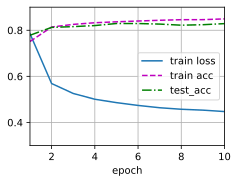

In [ ]:
def train(net, train_iter, test_iter, loss, num_epochs, updater):
  animator=Animator(xlabel='epoch', xlim=[1, num_epochs], ylim=[0.3, 0.9], legend=['train loss', 'train acc', 'test_acc'])
  for epoch in range(num_epochs):
    train_metrics=train_epoch(net, train_iter, loss, updater)
    test_acc=evaluate_accuracy(net, test_iter)
    animator.add(epoch+1, train_metrics+(test_acc,))
  train_loss, train_acc=train_metrics
  assert train_loss < 0.5, train_loss
  assert train_acc <= 1 and train_acc > 0.7, train_acc
  assert test_acc <= 1 and test_acc > 0.7, test_acc

lr=0.1
def updater(batch_size):
  return d2l.sgd([W, b], lr, batch_size)

num_epochs=10
train(net, train_iter, test_iter, cross_entropy, num_epochs, updater)

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:432: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


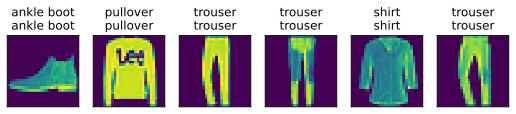

In [ ]:
def predict(net, test_iter, n=6):
  for X, y in test_iter:
    break
  trues=d2l.get_fashion_mnist_labels(y)
  preds=d2l.get_fashion_mnist_labels(net(X).argmax(axis=1))
  titles=[true+'\n'+pred for true, pred in zip(trues, preds)]
  d2l.show_images(X[0:n].reshape((n, 28, 28)), 1, n, titles=titles[0:n])

predict(net, test_iter)

## 3.7 concise implementation of softmax

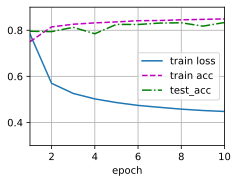

In [ ]:
import torch
from torch import nn
from d2l import torch as d2l

batch_size=256
train_iter, test_iter=d2l.load_data_fashion_mnist(batch_size)

net=nn.Sequential(nn.Flatten(), nn.Linear(784, 10))

def init_weights(m):
  if type(m)==nn.Linear:
    nn.init.normal_(m.weight, std=0.01)

net.apply(init_weights)
loss=nn.CrossEntropyLoss(reduction='none')
trainer=torch.optim.SGD(net.parameters(), lr=0.1)
num_epochs=10

# 替换原本报错的 d2l.train_ch3，使用我们在前面编写的本地 train 函数进行训练
train(net, train_iter, test_iter, loss, num_epochs, trainer)